# 02 — Модель (LightGBM)

Пайплайн:
1. зібрати ознаки з 7 таблиць (`src.features`);
2. OrdinalEncoder + медіанна імпутація;
3. LightGBM з early stopping;
4. 5-fold OOF ROC-AUC, hold-out, поріг за F1;
5. важливість ознак і SHAP.

Перший запуск збереже кеш `data/processed/train_features.parquet`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve,
    precision_recall_curve, confusion_matrix, classification_report,
)
from sklearn.model_selection import train_test_split

from src.config import FIGURES_DIR, MODELS_DIR, RANDOM_STATE, TARGET
from src.features import load_or_build_features
from src.preprocess import prepare_data
from src.train import best_f1_threshold, fit_final, make_lgbm, oof_cv, save_artifacts

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / name, dpi=120, bbox_inches='tight')
    print('saved', name)

## 1. Ознаки

In [2]:
df = load_or_build_features(include_bureau_balance=True)
print(df.shape)
print('default rate:', f"{df[TARGET].mean():.2%}")
df.head()

Завантаження таблиць...
application_train: 307,511 рядків × 122 колонок  [parquet]
bureau: 1,716,428 рядків × 17 колонок  [parquet]
previous_application: 1,670,214 рядків × 37 колонок  [parquet]
pos_cash_balance: 10,001,358 рядків × 8 колонок  [parquet]
installments_payments: 13,605,401 рядків × 8 колонок  [parquet]
credit_card_balance: 3,840,312 рядків × 24 колонок  [parquet]

Побудова ознак...
  + bureau                   11 ознак
bureau_balance: 54,599,850 рядків × 3 колонок  [parquet]
  + bureau_balance           4 ознак
  + previous_application     12 ознак
  + pos_cash                 8 ознак
  + installments             9 ознак
  + credit_card              10 ознак

Матриця ознак: 307,511 рядків × 186 колонок
Збережено: C:\Home Credit Default Risk\Home-Credit-Default-Risk\data\processed\train_features.parquet
(307511, 186)
default rate: 8.07%


,sk_id_curr,target,name_contract_type,code_gender,flag_own_car,flag_own_realty,cnt_children,amt_income_total,amt_credit,amt_annuity,...,cc_months_count,cc_avg_balance,cc_max_balance,cc_avg_credit_limit,cc_avg_drawings,cc_avg_payment,cc_avg_receivable,cc_max_dpd,cc_avg_dpd,cc_utilization
0,100281,0,Cash loans,F,N,Y,1,112500.0,675000.0,21906.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,100282,1,Revolving loans,F,Y,Y,0,73341.0,135000.0,6750.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,100283,0,Cash loans,F,N,Y,0,135000.0,747000.0,38268.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,100284,0,Cash loans,M,Y,Y,2,180000.0,675000.0,29862.0,...,30.0,9632.537,146882.61,450000.0,9736.311,10470.337759,9383.586,8.0,0.266667,0.021406
4,100285,0,Revolving loans,F,N,Y,0,112500.0,180000.0,9000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
X, y, num_cols, cat_cols, preprocessor = prepare_data(df)
print(f'X={X.shape}  num={len(num_cols)}  cat={len(cat_cols)}')

Ознаки: 168 числових, 16 категоріальних
TARGET: {0: 282686, 1: 24825}  (default rate 8.07%)
X=(307511, 184)  num=168  cat=16


## 2. 5-fold OOF CV

На кожному фолді препроцесор фітиться лише на train, LightGBM зупиняється по AUC валідації.

In [4]:
oof, cv_scores = oof_cv(X, y, preprocessor, n_splits=5)
print('OOF AUC:', roc_auc_score(y, oof))
print('OOF AP :', average_precision_score(y, oof))

  fold 1: AUC=0.7792  best_iter=318
  fold 2: AUC=0.7790  best_iter=343
  fold 3: AUC=0.7800  best_iter=346
  fold 4: AUC=0.7809  best_iter=344
  fold 5: AUC=0.7773  best_iter=457
  CV AUC: 0.7793 ± 0.0012
OOF AUC: 0.7792208077257784
OOF AP : 0.2727406546675747


## 3. Hold-out 20%

In [5]:
from sklearn.base import clone
import lightgbm as lgb

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
prep = clone(preprocessor)
X_tr_p = prep.fit_transform(X_tr)
X_te_p = prep.transform(X_te)
feature_names = list(prep.get_feature_names_out())

model = make_lgbm()
model.fit(
    X_tr_p, y_tr,
    eval_set=[(X_te_p, y_te)],
    eval_metric='auc',
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)],
)
y_prob = model.predict_proba(X_te_p)[:, 1]
thr, f1 = best_f1_threshold(y_te, y_prob)
y_pred = (y_prob >= thr).astype(int)

test_auc = roc_auc_score(y_te, y_prob)
test_ap = average_precision_score(y_te, y_prob)
print(f'best_iter={model.best_iteration_}')
print(f'AUC={test_auc:.4f}  AP={test_ap:.4f}  F1={f1:.4f} @ thr={thr:.2f}')
print(classification_report(y_te, y_pred, digits=3))

best_iter=335
AUC=0.7819  AP=0.2738  F1=0.3345 @ thr=0.67
              precision    recall  f1-score   support

           0      0.948     0.896     0.921     56538
           1      0.270     0.438     0.335      4965

    accuracy                          0.859     61503
   macro avg      0.609     0.667     0.628     61503
weighted avg      0.893     0.859     0.874     61503



saved 08_metrics.png


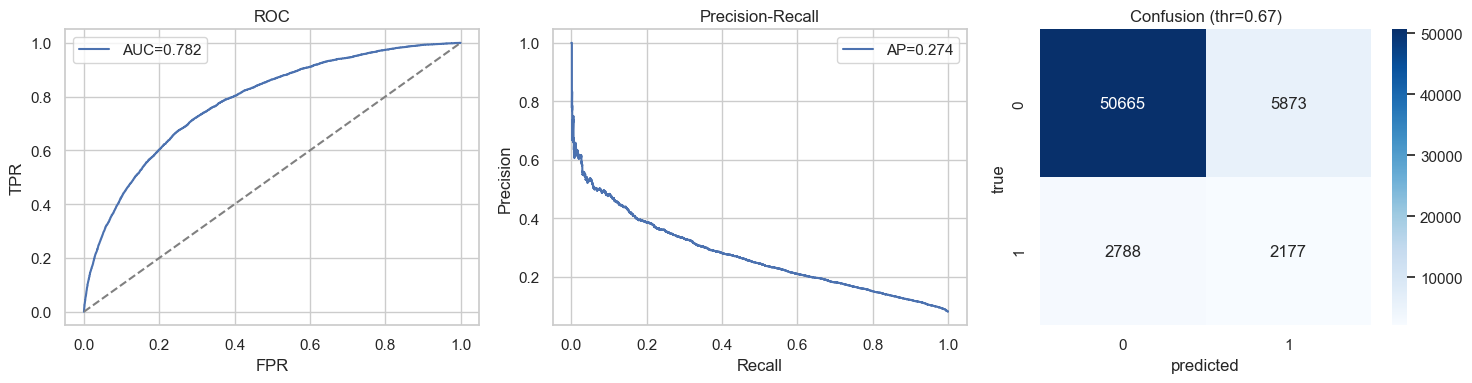

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

fpr, tpr, _ = roc_curve(y_te, y_prob)
axes[0].plot(fpr, tpr, label=f'AUC={test_auc:.3f}')
axes[0].plot([0, 1], [0, 1], ls='--', c='grey')
axes[0].set_title('ROC')
axes[0].set_xlabel('FPR')
axes[0].set_ylabel('TPR')
axes[0].legend()

prec, rec, _ = precision_recall_curve(y_te, y_prob)
axes[1].plot(rec, prec, label=f'AP={test_ap:.3f}')
axes[1].set_title('Precision-Recall')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

cm = confusion_matrix(y_te, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2])
axes[2].set_title(f'Confusion (thr={thr:.2f})')
axes[2].set_xlabel('predicted')
axes[2].set_ylabel('true')
savefig('08_metrics.png')
plt.show()

## 4. Важливість ознак

,feature,importance
112,ext_source_mean,288
143,pos_avg_future,280
109,goods_credit_ratio,270
27,ext_source_1,231
3,amt_annuity,227
28,ext_source_2,203
29,ext_source_3,193
151,inst_total_payment,190
9,days_id_publish,189
113,ext_source_min,185


saved 09_importance.png


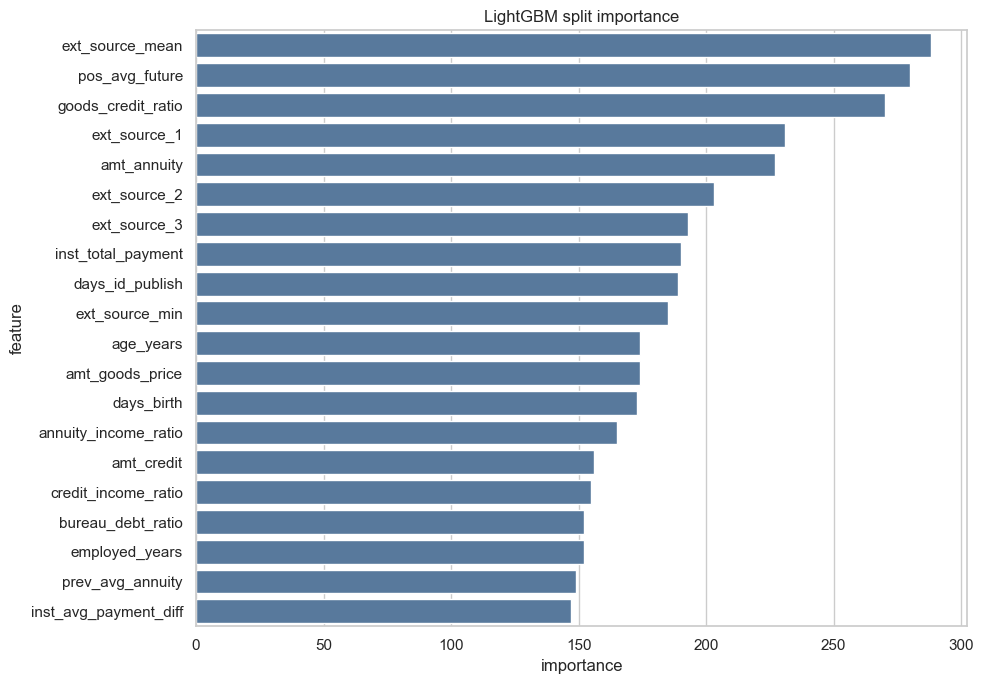

In [7]:
imp = pd.DataFrame({
    'feature': feature_names,
    'importance': model.feature_importances_,
}).sort_values('importance', ascending=False)
display(imp.head(20))

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=imp.head(20), x='importance', y='feature', ax=ax, color='#4C78A8')
ax.set_title('LightGBM split importance')
savefig('09_importance.png')
plt.show()

## 5. SHAP

Підвибірка hold-out, щоб explainer відпрацював за хвилини, а не за годину.

saved 10_shap_summary.png


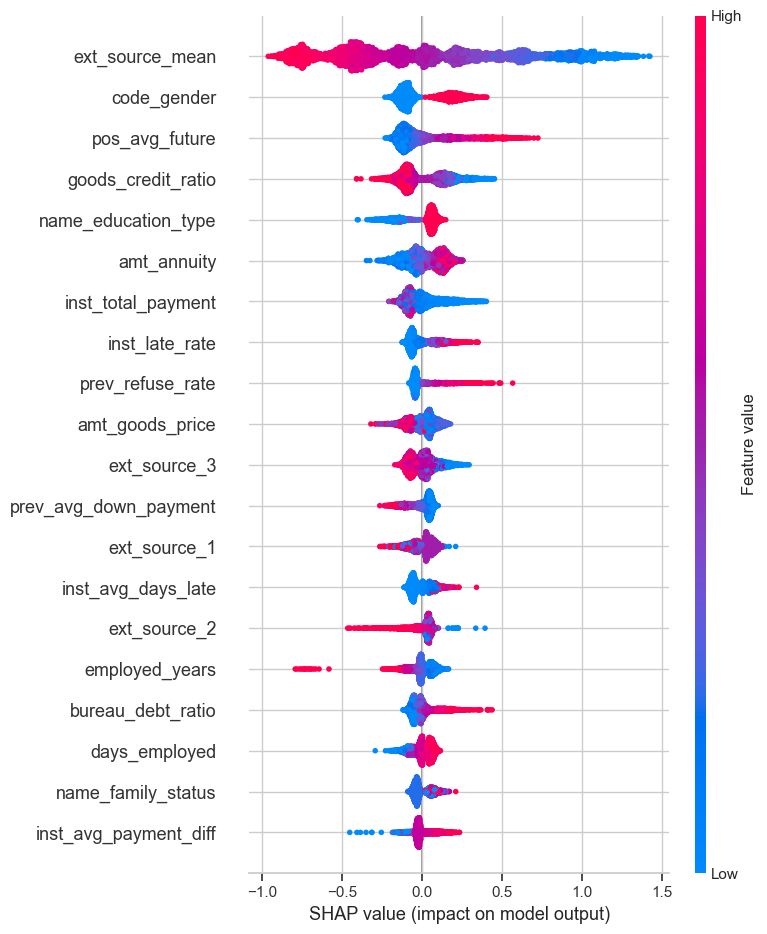

In [8]:
import shap

rng = np.random.RandomState(RANDOM_STATE)
n = min(4000, X_te_p.shape[0])
idx = rng.choice(X_te_p.shape[0], size=n, replace=False)
X_shap = X_te_p[idx]

explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(X_shap)
if isinstance(sv, list):
    sv = sv[1]

shap.summary_plot(sv, X_shap, feature_names=feature_names, show=False, max_display=20)
savefig('10_shap_summary.png')
plt.show()

## 6. Фінальна модель на всіх даних

In [9]:
n_est = model.best_iteration_ or 400
pipeline = fit_final(X, y, preprocessor, n_est)
save_artifacts(pipeline, cv_scores, test_auc, test_ap, thr, f1)
print('артефакти:', MODELS_DIR)


Модель: C:\Home Credit Default Risk\Home-Credit-Default-Risk\artifacts\models\lgbm_default_risk.pkl
            feature  importance
     pos_avg_future         305
    ext_source_mean         293
       ext_source_1         255
 goods_credit_ratio         241
        amt_annuity         225
 inst_total_payment         207
       ext_source_2         184
    amt_goods_price         183
    days_id_publish         180
         days_birth         175
     ext_source_min         175
     inst_late_rate         167
credit_income_ratio         166
  bureau_debt_ratio         166
          age_years         163
артефакти: C:\Home Credit Default Risk\Home-Credit-Default-Risk\artifacts\models


## Інтерпретація

- Очікуваний hold-out ROC-AUC порядку **0.76–0.78** на цій постановці (без важкого stacking).
- `EXT_SOURCE_*`, вік, платіжна дисципліна (`inst_avg_days_late`) і борг бюро зазвичай у топі.
- Поріг ~0.15–0.25 (не 0.5): через дисбаланс і `class_weight` ймовірності зсунуті.
- CLI: `python -m src.train` з кореня репозиторію.